In [1]:
import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)

In [2]:
match = pd.read_csv('NPL matches.csv')

In [3]:
delivery = pd.read_csv('NPL-2024-2025-combined.csv')

In [4]:
match.sample(5)

,id,season,date,time,venue,stage,city,team_1,team_2,toss_winner,toss_decision,result,dls_applied,super_over,winner,team_1_runs,team_2_runs,team_1_overs_played,team_2_overs_played,team_1_wickets,team_2_wickets,team_1_runs_from_extra,team_2_runs_from_extra,win_by_runs,win_by_wickets,player_of_the_match,over_balls,extra_balls,total_ball_bowled
19,20,2024,12/12/2024,Day,Tribhuvan University International Cricket Gro...,League,Kathmandu,Biratnagar Kings,Pokhara Avengers,Biratnagar Kings,bat,normal,0,1,Pokhara Avengers,139,139,20.0,20.0,7,6,4,7,0,0,Raymon Reifer,240,4,244
26,27,2024,15/12/2024,Day,Tribhuvan University International Cricket Gro...,League,Kathmandu,Sudurpaschim Royals,Pokhara Avengers,Pokhara Avengers,field,normal,0,0,Sudurpaschim Royals,153,148,20.0,19.4,7,10,14,15,5,0,Scott Kuggeleijn,238,11,249
60,61,2025,09/12/2025,Day/Night,Tribhuvan University International Cricket Gro...,Qualifier 1,Kathmandu,Sudurpaschim Royals,Biratnagar Kings,Biratnagar Kings,field,normal,0,0,Sudurpaschim Royals,155,78,20.0,14.1,7,10,6,1,77,0,Binod Bhandari,205,3,208
9,10,2024,06/12/2024,Day,Tribhuvan University International Cricket Gro...,League,Kathmandu,Chitwan Rhinos,Karnali Yaks,Karnali Yaks,field,normal,0,0,Karnali Yaks,130,132,20.0,19.5,7,4,5,9,0,6,Bipin Sharma,239,9,248
0,1,2024,30/11/2024,Day,Tribhuvan University International Cricket Gro...,League,Kathmandu,Biratnagar Kings,Janakpur Bolts,Janakpur Bolts,field,normal,0,0,Janakpur Bolts,127,131,19.0,15.3,10,2,15,22,0,8,Lahiru Milantha,207,17,224


In [5]:
delivery[delivery['match_id'] == 24].head()

,match_id,inning,batting_team,bowling_team,ball_over,ball_result,bowler,batter,non_striker,shot_direction,player_out,dismissal_kind,fielders,batsman_runs,wide_runs,bye_runs,legbye_runs,noball_runs,extra_runs,total_runs,season
5358,24,1,Pokhara Avengers,Kathmandu Gurkhas,0.1,0,Shahab Alam,Dinesh Kharel,Andries Gous,mid on,NaN,NaN,NaN,0,0,0,0,0,0,0,2024
5359,24,1,Pokhara Avengers,Kathmandu Gurkhas,0.2,6,Shahab Alam,Dinesh Kharel,Andries Gous,mid wicket,NaN,NaN,NaN,6,0,0,0,0,0,6,2024
5360,24,1,Pokhara Avengers,Kathmandu Gurkhas,0.3,0,Shahab Alam,Dinesh Kharel,Andries Gous,mid off,NaN,NaN,NaN,0,0,0,0,0,0,0,2024
5361,24,1,Pokhara Avengers,Kathmandu Gurkhas,0.4,1,Shahab Alam,Dinesh Kharel,Andries Gous,mid on,NaN,NaN,NaN,1,0,0,0,0,0,1,2024
5362,24,1,Pokhara Avengers,Kathmandu Gurkhas,0.5,0,Shahab Alam,Andries Gous,Dinesh Kharel,NaN,NaN,NaN,NaN,0,0,0,0,0,0,0,2024


In [6]:
delivery['bowling_team'].unique()

<StringArray>
[     'Janakpur Bolts',    'Biratnagar Kings',      'Chitwan Rhinos',
   'Kathmandu Gurkhas',        'Karnali Yaks', 'Sudurpaschim Royals',
    'Pokhara Avengers',       'Lumbini Lions',   'Kathmandu Gorkhas']
Length: 9, dtype: str

In [7]:
delivery['batting_team'] = delivery['batting_team'].str.replace('Kathmandu Gurkhas', 'Kathmandu Gorkhas')
delivery['bowling_team'] = delivery['bowling_team'].str.replace('Kathmandu Gurkhas', 'Kathmandu Gorkhas')

In [8]:
delivery['bowling_team'].unique()

<StringArray>
[     'Janakpur Bolts',    'Biratnagar Kings',      'Chitwan Rhinos',
   'Kathmandu Gorkhas',        'Karnali Yaks', 'Sudurpaschim Royals',
    'Pokhara Avengers',       'Lumbini Lions']
Length: 8, dtype: str

In [9]:
match.shape

(64, 29)

In [10]:
delivery.shape

(14924, 21)

In [11]:
total_score_df = delivery.groupby(["match_id", "inning"]).sum()["total_runs"].reset_index()

In [12]:
total_score_df

,match_id,inning,total_runs
0,1,1,127
1,1,2,131
2,2,1,111
3,2,2,114
4,3,1,141
...,...,...,...
123,62,2,112
124,63,1,134
125,63,2,94
126,64,1,85


In [13]:
total_score_df = total_score_df[total_score_df['inning'] == 1] 

In [14]:
total_score_df

,match_id,inning,total_runs
0,1,1,127
2,2,1,111
4,3,1,141
6,4,1,182
8,5,1,161
...,...,...,...
118,60,1,129
120,61,1,155
122,62,1,111
124,63,1,134


In [15]:
match_df = match.merge(total_score_df[['match_id', 'total_runs']], left_on='id', right_on='match_id')

In [16]:
match_df.sample(10)

,id,season,date,time,venue,stage,city,team_1,team_2,toss_winner,toss_decision,result,dls_applied,super_over,winner,team_1_runs,team_2_runs,team_1_overs_played,team_2_overs_played,team_1_wickets,team_2_wickets,team_1_runs_from_extra,team_2_runs_from_extra,win_by_runs,win_by_wickets,player_of_the_match,over_balls,extra_balls,total_ball_bowled,match_id,total_runs
48,49,2025,29/11/2025,Day,Tribhuvan University International Cricket Gro...,League,Kathmandu,Pokhara Avengers,Lumbini Lions,Lumbini Lions,field,normal,0,0,Lumbini Lions,150,151,20.0,19.4,5,7,9,6,0,3,Rohit Paudel,238,13,251,49,150
31,32,2024,21/12/2024,Day,Tribhuvan University International Cricket Gro...,Final,Kathmandu,Sudurpaschim Royals,Janakpur Bolts,Sudurpaschim Royals,bat,normal,0,0,Janakpur Bolts,184,185,20.0,19.2,9,5,8,18,0,5,Lahiru Milantha,236,8,244,32,184
19,20,2024,12/12/2024,Day,Tribhuvan University International Cricket Gro...,League,Kathmandu,Biratnagar Kings,Pokhara Avengers,Biratnagar Kings,bat,normal,0,1,Pokhara Avengers,139,139,20.0,20.0,7,6,4,7,0,0,Raymon Reifer,240,4,244,20,139
20,21,2024,12/12/2024,Day,Tribhuvan University International Cricket Gro...,League,Kathmandu,Kathmandu Gorkhas,Janakpur Bolts,Kathmandu Gorkhas,bat,normal,0,0,Janakpur Bolts,101,105,19.3,15.5,10,5,11,5,0,5,Lalit Rajbanshi,212,5,217,21,101
4,5,2024,03/12/2024,Day,Tribhuvan University International Cricket Gro...,League,Kathmandu,Chitwan Rhinos,Pokhara Avengers,Pokhara Avengers,field,normal,0,0,Chitwan Rhinos,161,74,20.0,13.2,7,10,5,11,87,0,Rijan Dhakal,200,9,209,5,161
13,14,2024,08/12/2024,Day,Tribhuvan University International Cricket Gro...,League,Kathmandu,Janakpur Bolts,Lumbini Lions,Lumbini Lions,field,normal,0,0,Janakpur Bolts,136,135,20.0,20.0,9,8,15,17,1,0,Harsh Thaker,240,9,249,14,136
43,44,2025,26/11/2025,Day/Night,Tribhuvan University International Cricket Gro...,League,Kathmandu,Chitwan Rhinos,Biratnagar Kings,Biratnagar Kings,field,normal,0,0,Chitwan Rhinos,174,126,20.0,16.5,5,10,4,6,48,0,Ranjit Kumar,221,3,224,44,174
50,51,2025,30/11/2025,Day/Night,Tribhuvan University International Cricket Gro...,League,Kathmandu,Karnali Yaks,Kathmandu Gorkhas,Karnali Yaks,bat,normal,0,0,Kathmandu Gorkhas,149,155,20.0,18.0,7,5,5,8,0,5,Gerhard Erasmus,228,5,233,51,149
62,63,2025,11/12/2025,Day/Night,Tribhuvan University International Cricket Gro...,Qualifier 2,Kathmandu,Lumbini Lions,Biratnagar Kings,Biratnagar Kings,field,normal,0,0,Lumbini Lions,134,94,20.0,17.5,8,10,4,2,40,0,Tilak Bhandari,227,4,231,63,134
10,11,2024,06/12/2024,Day,Tribhuvan University International Cricket Gro...,League,Kathmandu,Lumbini Lions,Pokhara Avengers,Lumbini Lions,bat,normal,0,0,Pokhara Avengers,170,176,20.0,16.5,4,0,10,11,0,10,Andries Gous,221,6,227,11,170


In [17]:
match_df.columns

Index(['id', 'season', 'date', 'time', 'venue', 'stage', 'city', 'team_1',
       'team_2', 'toss_winner', 'toss_decision', 'result', 'dls_applied',
       'super_over', 'winner', 'team_1_runs', 'team_2_runs',
       'team_1_overs_played', 'team_2_overs_played', 'team_1_wickets',
       'team_2_wickets', 'team_1_runs_from_extra', 'team_2_runs_from_extra',
       'win_by_runs', 'win_by_wickets', 'player_of_the_match', 'over_balls',
       'extra_balls', 'total_ball_bowled', 'match_id', 'total_runs'],
      dtype='str')

In [18]:
match_df = match_df[match_df['dls_applied'] == 0]

In [19]:
match_df = match_df[match_df['super_over'] == 0]

In [20]:
match_df = match_df[['match_id', 'winner', 'total_runs']]

In [21]:
match_df

,match_id,winner,total_runs
0,1,Janakpur Bolts,127
1,2,Chitwan Rhinos,111
2,3,Janakpur Bolts,141
3,4,Sudurpaschim Royals,182
4,5,Chitwan Rhinos,161
...,...,...,...
59,60,Karnali Yaks,129
60,61,Sudurpaschim Royals,155
61,62,Lumbini Lions,111
62,63,Lumbini Lions,134


In [22]:
delivery_df = match_df.merge(delivery, on='match_id') 

In [23]:
delivery_df = delivery_df[delivery_df['inning'] == 2]

In [24]:
delivery_df.sample(10)

,match_id,winner,total_runs_x,inning,batting_team,bowling_team,ball_over,ball_result,bowler,batter,non_striker,shot_direction,player_out,dismissal_kind,fielders,batsman_runs,wide_runs,bye_runs,legbye_runs,noball_runs,extra_runs,total_runs_y,season
6690,30,Sudurpaschim Royals,139,2,Sudurpaschim Royals,Janakpur Bolts,7.3,W,Kishore Mahato,Saif Zaib,Binod Bhandari,NaN,Saif Zaib,Caught,James Neesham,0,0,0,0,0,0,0,2024
2949,13,Karnali Yaks,133,2,Biratnagar Kings,Karnali Yaks,5.3,W,Nandan Yadav,Aqib Ilyas,Naren Bhatta,NaN,Aqib Ilyas,Bowled,NaN,0,0,0,0,0,0,0,2024
3467,15,Chitwan Rhinos,164,2,Sudurpaschim Royals,Chitwan Rhinos,8.6,0,Kushal Malla,Ishan Pandey,Dilpreet Bajwa,mid wicket,NaN,NaN,NaN,0,0,0,0,0,0,0,2024
10518,46,Pokhara Avengers,155,2,Janakpur Bolts,Pokhara Avengers,18.1,6,Kushal Bhurtel,Wayne Parnell,Lalit Rajbanshi,long off,NaN,NaN,NaN,6,0,0,0,0,0,6,2025
9772,43,Kathmandu Gorkhas,157,2,Lumbini Lions,Kathmandu Gorkhas,11.3,1,Gerhard Erasmus,Dilip Nath,Ruben Trumpelmann,mid wicket,NaN,NaN,NaN,1,0,0,0,0,0,1,2025
2989,13,Karnali Yaks,133,2,Biratnagar Kings,Karnali Yaks,11.6,6,Unish Singh,Dipak Bohara,Nicholas Kirton,mid on,NaN,NaN,NaN,6,0,0,0,0,0,6,2024
7652,34,Chitwan Rhinos,166,2,Chitwan Rhinos,Karnali Yaks,9.6,0,Yuvraj Khatri,Kushal Malla,Ravi Bopara,covers,NaN,NaN,NaN,0,0,0,0,0,0,0,2025
9964,44,Chitwan Rhinos,174,2,Biratnagar Kings,Chitwan Rhinos,3.1,0,Kamal Singh Airee,Sam Heazlett,Naren Bhatta,covers,NaN,NaN,NaN,0,0,0,0,0,0,0,2025
3771,16,Lumbini Lions,167,2,Chitwan Rhinos,Lumbini Lions,19.6,6,Bibek Yadav,Nar Sarki,Rijan Dhakal,mid on,NaN,NaN,NaN,6,0,0,0,0,0,6,2024
12405,54,Lumbini Lions,144,2,Lumbini Lions,Biratnagar Kings,13.6,0,Sandeep Lamichhane,Niroshan Dickwella,Dilip Nath,NaN,NaN,NaN,NaN,0,0,0,0,0,0,0,2025


In [25]:
delivery_df['current_score'] = delivery_df.groupby('match_id')['total_runs_y'].cumsum()

In [26]:
delivery_df['runs_left'] = delivery_df['total_runs_x'] + 1 - delivery_df['current_score']
# adding 1 for target is 1 greater than total runs from first inning

In [27]:
delivery_df['balls_left'] = 120 - (
    delivery_df['ball_over'].astype(str).apply(
        lambda x: int(x.split('.')[0]) * 6 + int(x.split('.')[1])
    )
)

In [28]:
delivery_df.head()

,match_id,winner,total_runs_x,inning,batting_team,bowling_team,ball_over,ball_result,bowler,batter,non_striker,shot_direction,player_out,dismissal_kind,fielders,batsman_runs,wide_runs,bye_runs,legbye_runs,noball_runs,extra_runs,total_runs_y,season,current_score,runs_left,balls_left
121,1,Janakpur Bolts,127,2,Janakpur Bolts,Biratnagar Kings,0.1,5w,Chris Sole,Anil Sah,Aasif Sheikh,NaN,NaN,NaN,NaN,0,5,0,0,0,5,5,2024,5,123,119
122,1,Janakpur Bolts,127,2,Janakpur Bolts,Biratnagar Kings,0.1,1w,Chris Sole,Anil Sah,Aasif Sheikh,NaN,NaN,NaN,NaN,0,1,0,0,0,1,1,2024,6,122,119
123,1,Janakpur Bolts,127,2,Janakpur Bolts,Biratnagar Kings,0.1,5,Chris Sole,Anil Sah,Aasif Sheikh,point,NaN,NaN,NaN,5,0,0,0,0,0,5,2024,11,117,119
124,1,Janakpur Bolts,127,2,Janakpur Bolts,Biratnagar Kings,0.2,0,Chris Sole,Aasif Sheikh,Anil Sah,NaN,NaN,NaN,NaN,0,0,0,0,0,0,0,2024,11,117,118
125,1,Janakpur Bolts,127,2,Janakpur Bolts,Biratnagar Kings,0.3,0,Chris Sole,Aasif Sheikh,Anil Sah,fine leg,NaN,NaN,NaN,0,0,0,0,0,0,0,2024,11,117,117


In [29]:
delivery_df['player_out'] = delivery_df['player_out'].fillna("0")
delivery_df['player_out'] = delivery_df['player_out'].apply(lambda x:x if x == "0" else "1")
delivery_df['player_out'] = delivery_df['player_out'].astype('int')
wickets = delivery_df.groupby('match_id')['player_out'].cumsum().values
delivery_df['wickets'] = 10 - wickets

In [30]:
# # Create binary wicket column
# delivery_df['player_out_binary'] = delivery_df['player_out'].notna().astype(int)

# # Calculate cumulative wickets lost
# wickets = delivery_df.groupby(['match_id', 'inning'])['player_out_binary'].cumsum()

# # Calculate remaining wickets
# delivery_df['wickets'] = 10 - wickets

In [31]:
delivery_df.head()

,match_id,winner,total_runs_x,inning,batting_team,bowling_team,ball_over,ball_result,bowler,batter,non_striker,shot_direction,player_out,dismissal_kind,fielders,batsman_runs,wide_runs,bye_runs,legbye_runs,noball_runs,extra_runs,total_runs_y,season,current_score,runs_left,balls_left,wickets
121,1,Janakpur Bolts,127,2,Janakpur Bolts,Biratnagar Kings,0.1,5w,Chris Sole,Anil Sah,Aasif Sheikh,NaN,0,NaN,NaN,0,5,0,0,0,5,5,2024,5,123,119,10
122,1,Janakpur Bolts,127,2,Janakpur Bolts,Biratnagar Kings,0.1,1w,Chris Sole,Anil Sah,Aasif Sheikh,NaN,0,NaN,NaN,0,1,0,0,0,1,1,2024,6,122,119,10
123,1,Janakpur Bolts,127,2,Janakpur Bolts,Biratnagar Kings,0.1,5,Chris Sole,Anil Sah,Aasif Sheikh,point,0,NaN,NaN,5,0,0,0,0,0,5,2024,11,117,119,10
124,1,Janakpur Bolts,127,2,Janakpur Bolts,Biratnagar Kings,0.2,0,Chris Sole,Aasif Sheikh,Anil Sah,NaN,0,NaN,NaN,0,0,0,0,0,0,0,2024,11,117,118,10
125,1,Janakpur Bolts,127,2,Janakpur Bolts,Biratnagar Kings,0.3,0,Chris Sole,Aasif Sheikh,Anil Sah,fine leg,0,NaN,NaN,0,0,0,0,0,0,0,2024,11,117,117,10


In [32]:
# crr = runs/overs   OR    (runs/balls)*6
delivery_df['crr'] = (delivery_df['current_score'] / (120 - delivery_df['balls_left'])) * 6

In [33]:
# crr = runs_left/overs_left   OR    (runs_left/balls_left)*6
delivery_df['rrr'] = (delivery_df['runs_left'] / delivery_df['balls_left']) * 6

In [34]:
delivery_df.sample(5)

,match_id,winner,total_runs_x,inning,batting_team,bowling_team,ball_over,ball_result,bowler,batter,non_striker,shot_direction,player_out,dismissal_kind,fielders,batsman_runs,wide_runs,bye_runs,legbye_runs,noball_runs,extra_runs,total_runs_y,season,current_score,runs_left,balls_left,wickets,crr,rrr
2254,10,Karnali Yaks,130,2,Karnali Yaks,Chitwan Rhinos,10.3,1,Jan Nicol Loftie-Eaton,Shikhar Dhawan,Chadwick Walton,mid off,0,NaN,NaN,1,0,0,0,0,0,1,2024,56,75,57,9,5.333333,7.894737
2725,12,Sudurpaschim Royals,187,2,Lumbini Lions,Sudurpaschim Royals,9.3,1,Saif Zaib,Sundeep Jora,Bibek Yadav,mid wicket,0,NaN,NaN,1,0,0,0,0,0,1,2024,49,139,63,5,5.157895,13.238095
6209,28,Sudurpaschim Royals,101,2,Sudurpaschim Royals,Karnali Yaks,5.2,0,William Bosisto,Dipendra Singh Airee,Ishan Pandey,NaN,0,NaN,NaN,0,0,0,0,0,0,0,2024,28,74,88,7,5.250000,5.045455
12604,55,Kathmandu Gorkhas,165,2,Pokhara Avengers,Kathmandu Gorkhas,7.5,1,Milind Kumar,Kushal Bhurtel,Dhananjaya Lakshan,long on,0,NaN,NaN,1,0,0,0,0,0,1,2025,49,117,73,7,6.255319,9.616438
11253,49,Lumbini Lions,150,2,Lumbini Lions,Pokhara Avengers,19.3,0,Matt Taylor,Sundeep Jora,Sher Malla,third man,0,NaN,NaN,0,0,0,0,0,0,0,2025,147,4,3,3,7.538462,8.000000


In [35]:
def result(row):
    return 1 if row['batting_team'] == row['winner'] else 0

In [36]:
delivery_df['result'] = delivery_df.apply(result, axis = 1)

In [37]:
delivery_df.sample()

,match_id,winner,total_runs_x,inning,batting_team,bowling_team,ball_over,ball_result,bowler,batter,non_striker,shot_direction,player_out,dismissal_kind,fielders,batsman_runs,wide_runs,bye_runs,legbye_runs,noball_runs,extra_runs,total_runs_y,season,current_score,runs_left,balls_left,wickets,crr,rrr,result
5022,23,Biratnagar Kings,181,2,Chitwan Rhinos,Biratnagar Kings,4.6,4,Basir Ahamad,Santosh Karki,Ravi Bopara,square leg,0,NaN,NaN,4,0,0,0,0,0,4,2024,28,154,90,9,5.6,10.266667,0


In [38]:
final_df = delivery_df[['batting_team', 'bowling_team', 'runs_left', 'balls_left', 'wickets', 'total_runs_x', 'crr', 'rrr', 'result']]

In [39]:
final_df.head()

,batting_team,bowling_team,runs_left,balls_left,wickets,total_runs_x,crr,rrr,result
121,Janakpur Bolts,Biratnagar Kings,123,119,10,127,30.0,6.201681,1
122,Janakpur Bolts,Biratnagar Kings,122,119,10,127,36.0,6.151261,1
123,Janakpur Bolts,Biratnagar Kings,117,119,10,127,66.0,5.899160,1
124,Janakpur Bolts,Biratnagar Kings,117,118,10,127,33.0,5.949153,1
125,Janakpur Bolts,Biratnagar Kings,117,117,10,127,22.0,6.000000,1


In [40]:
final_df = final_df.sample(final_df.shape[0])

In [41]:
final_df.sample()

,batting_team,bowling_team,runs_left,balls_left,wickets,total_runs_x,crr,rrr,result
6738,Sudurpaschim Royals,Janakpur Bolts,23,27,8,139,7.548387,5.111111,1


In [42]:
final_df.shape

(6934, 9)

In [43]:
final_df = final_df[final_df['balls_left'] != 0]

In [44]:
final_df.shape

(6922, 9)

In [45]:
X = final_df.iloc[:,:-1]
y = final_df.iloc[:,-1]
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 1)

In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

trf = ColumnTransformer([
    ('trf', OneHotEncoder(sparse_output=False, drop='first'),['batting_team', 'bowling_team'])
], remainder = 'passthrough')

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

In [48]:
pipe = Pipeline(steps=[
    ('step1', trf),
    ('step2', LogisticRegression(solver = 'liblinear'))
    # ('step2', RandomForestClassifier())
])

In [49]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('step1', ...), ('step2', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['batting_team','bowling_team','runs_left',...,'total_runs_x','crr','rrr']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('trf', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns th

In [50]:
y_pred = pipe.predict(X_test)

In [51]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.8505415162454874

In [52]:
pipe.predict_proba(X_test)

array([[9.92421472e-01, 7.57852764e-03],
       [9.99083847e-01, 9.16152684e-04],
       [9.99588782e-01, 4.11218408e-04],
       ...,
       [1.08935226e-03, 9.98910648e-01],
       [7.38129492e-01, 2.61870508e-01],
       [2.68183099e-01, 7.31816901e-01]], shape=(1385, 2))

In [53]:
def match_progression(x_df, match_id, pipe):
    match = x_df[x_df['match_id'] == match_id]
    match = match[(match['balls_left'] % 6 == 0)]
    temp_df = match[['batting_team', 'bowling_team', 'runs_left', 'balls_left', 'wickets', 'total_runs_x', 'crr', 'rrr', 'result']]
    temp_df = temp_df[temp_df['balls_left'] != 0]
    result = pipe.predict_proba(temp_df)
    temp_df['lose_p'] = np.round(result.T[0]*100, 1)
    temp_df['win_p'] = np.round(result.T[1]*100, 1)
    temp_df['end_of_over'] = range(1, temp_df.shape[0] + 1)
    
    target = temp_df['total_runs_x'].values[0]
    runs = list(temp_df['runs_left'].values)
    new_runs = runs[:]
    runs.insert(0, target)
    #temp_df['runs_after_over'] = np.array(runs)[:1] - np.array(new_runs)
    temp_df['runs_after_over'] = np.array(runs[:-1]) - np.array(runs[1:])
    
    wickets = list(temp_df['wickets'].values)
    new_wickets = wickets[:]
    new_wickets.insert(0,10)
    wickets.append(0)
    w = np.array(wickets)
    nw = np.array(new_wickets)
    temp_df['wickets_in_over'] = (nw - w)[0:temp_df.shape[0]]

    print(f"Target - {target}")
    temp_df = temp_df[['end_of_over', 'runs_after_over', 'wickets_in_over', 'lose_p', 'win_p']]
    return temp_df, target

In [54]:
temp_df, target = match_progression(delivery_df, 13, pipe)
temp_df

Target - 133


,end_of_over,runs_after_over,wickets_in_over,lose_p,win_p
2920,1,10,0,6.4,93.6
2921,2,2,0,5.7,94.3
2928,3,5,1,11.6,88.4
2934,4,11,0,6.3,93.7
2940,5,0,1,18.0,82.0
2946,6,4,0,16.1,83.9
2953,7,3,1,34.2,65.8
2959,8,2,0,35.6,64.4
2965,9,5,0,31.8,68.2
2971,10,5,1,53.0,47.0


Text(0.5, 1.0, 'Target - 133')

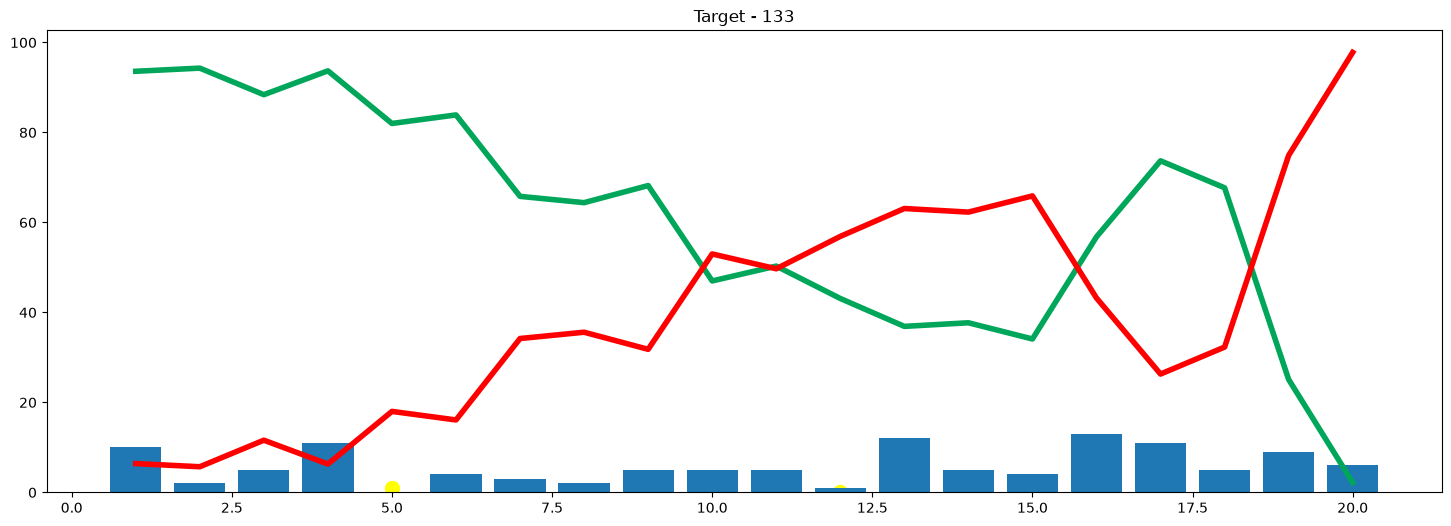

In [55]:
import matplotlib.pyplot as plt
plt.figure(figsize = (18, 6))

plt.plot(temp_df['end_of_over'], temp_df['win_p'], color='#00a65a', linewidth=4)
plt.plot(temp_df['end_of_over'], temp_df['lose_p'], color='red', linewidth=4)
plt.scatter(temp_df['end_of_over'], temp_df['wickets_in_over'],
            color='yellow', s=100, label='Wickets')
plt.bar(temp_df['end_of_over'], temp_df['runs_after_over'])
plt.title('Target - ' + str(target))

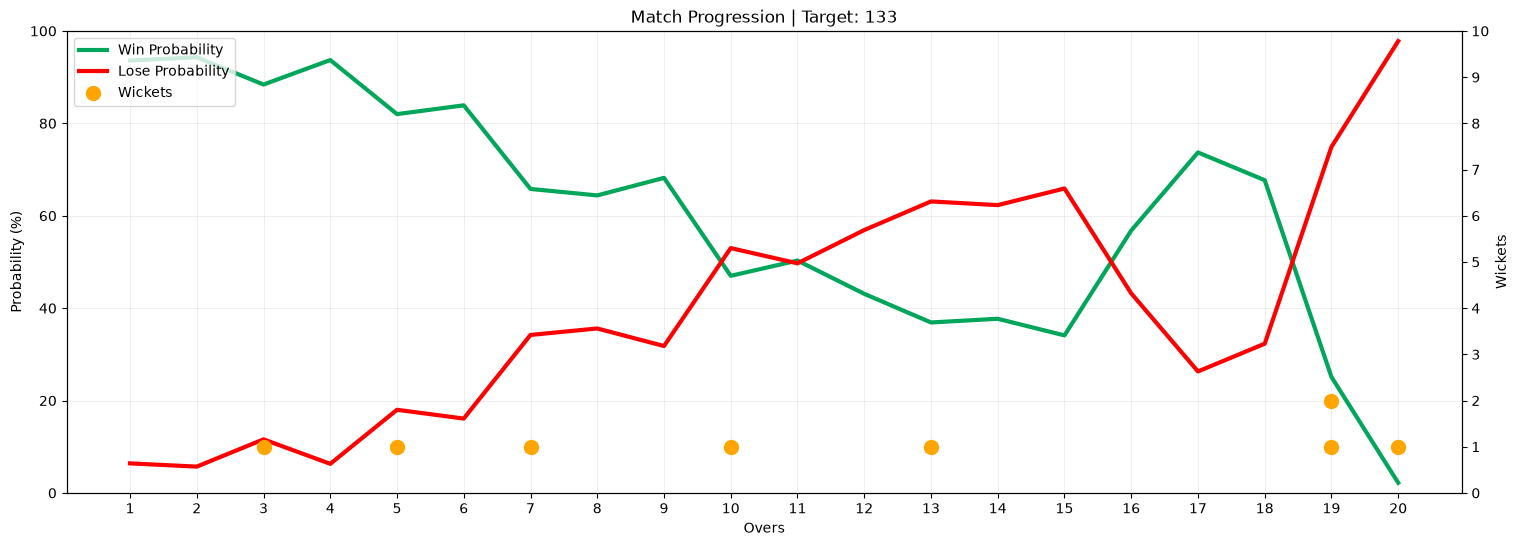

In [56]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(18, 6))

# First Y-axis: Win and lose probability
ax1.plot(temp_df['end_of_over'], temp_df['win_p'],
         color='#00a65a', linewidth=3, label='Win Probability')

ax1.plot(temp_df['end_of_over'], temp_df['lose_p'],
         color='red', linewidth=3, label='Lose Probability')

ax1.set_xlabel('Overs')
ax1.set_ylabel('Probability (%)')
ax1.set_ylim(0, 100)
ax1.set_xticks(range(1, 21))

# Second Y-axis: Wickets
ax2 = ax1.twinx()

# Filter only overs where wickets fell
wicket_df = temp_df[temp_df['wickets_in_over'] > 0]

# Plot individual dots for each wicket
for _, row in wicket_df.iterrows():
    ax2.scatter(
        [row['end_of_over']] * int(row['wickets_in_over']),
        range(1, int(row['wickets_in_over']) + 1),
        color='orange',
        s=100,
        zorder=3,
        label='Wickets' if row.name == wicket_df.index[0] else ""
    )

ax2.set_ylabel('Wickets')
ax2.set_ylim(0, 10)
ax2.set_yticks(range(0, 11))

# Title and combined legend
ax1.set_title('Match Progression | Target: ' + str(target))
ax1.grid(alpha=0.2)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.show()



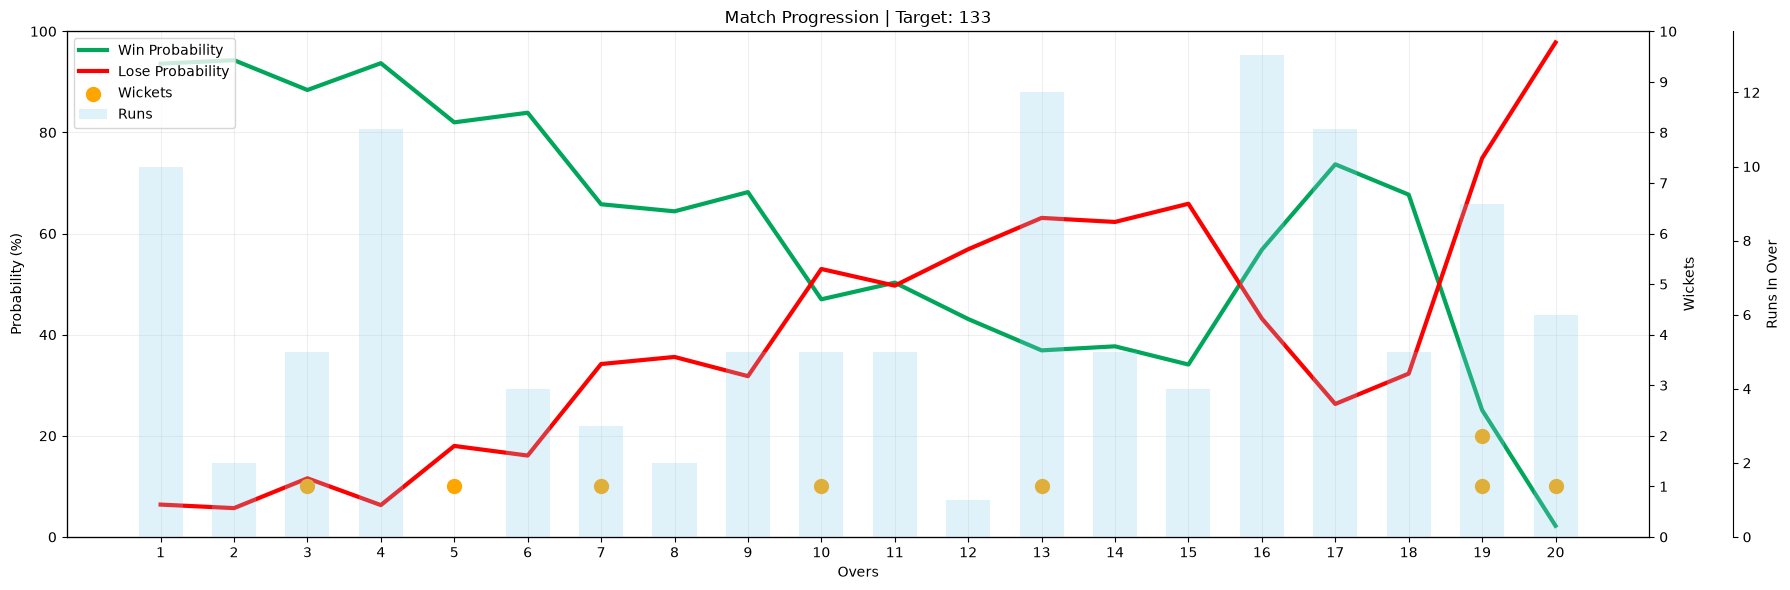

In [57]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(18, 6))

# First Y-axis: Win and lose probability
ax1.plot(temp_df['end_of_over'], temp_df['win_p'],
         color='#00a65a', linewidth=3, label='Win Probability')

ax1.plot(temp_df['end_of_over'], temp_df['lose_p'],
         color='red', linewidth=3, label='Lose Probability')

ax1.set_xlabel('Overs')
ax1.set_ylabel('Probability (%)')
ax1.set_ylim(0, 100)
ax1.set_xticks(range(1, 21))

# Second Y-axis: Wickets
ax2 = ax1.twinx()

wicket_df = temp_df[temp_df['wickets_in_over'] > 0]

for _, row in wicket_df.iterrows():
    ax2.scatter(
        [row['end_of_over']] * int(row['wickets_in_over']),
        range(1, int(row['wickets_in_over']) + 1),
        color='orange',
        s=100,
        zorder=4,
        label='Wickets' if row.name == wicket_df.index[0] else ""
    )

ax2.set_ylabel('Wickets')
ax2.set_ylim(0, 10)
ax2.set_yticks(range(0, 11))

# Third Y-axis: Runs
ax3 = ax1.twinx()
ax3.spines['right'].set_position(('outward', 60))

ax3.bar(temp_df['end_of_over'], temp_df['runs_after_over'],
        color='skyblue', alpha=0.25, width=0.6, label='Runs')

ax3.set_ylabel('Runs In Over')

# Title and combined legend
ax1.set_title('Match Progression | Target: ' + str(target))
ax1.grid(alpha=0.2)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
lines3, labels3 = ax3.get_legend_handles_labels()

ax1.legend(lines1 + lines2 + lines3,
           labels1 + labels2 + labels3,
           loc='upper left')

plt.tight_layout()
plt.show()

In [64]:
delivery_df['bowling_team'].unique()

<StringArray>
[   'Biratnagar Kings',   'Kathmandu Gorkhas',        'Karnali Yaks',
 'Sudurpaschim Royals',      'Chitwan Rhinos',       'Lumbini Lions',
    'Pokhara Avengers',      'Janakpur Bolts']
Length: 8, dtype: str

In [60]:
teams = [
    'Biratnagar Kings',   
    'Kathmandu Gorkhas',        
    'Karnali Yaks',
    'Sudurpaschim Royals',      
    'Chitwan Rhinos',       
    'Lumbini Lions',
    'Pokhara Avengers',      
    'Janakpur Bolts'
]

In [66]:
import pickle
pickle.dump(pipe, open('pipe.pkl', 'wb'))